# Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load Dataset

In [2]:
# NOTE: SteamGames_1000 only used for test run, SteamGames is the full dataset and used on real run
df = pd.read_csv("data/SteamGames_1000.csv")
df.head(5)

,Appid,Name,Type,ReleaseDate,Genres,Developers,Publishers,Description,price,Thumbnail,Tags,ReviewScore,PositiveReview,NegativeReview,OsRequirement,MemoryRequirement,CpuRequirement,Rank
0,3764200,Resident Evil Requiem,game,"Feb 26, 2026","Action,Adventure","CAPCOM Co., Ltd.","CAPCOM Co., Ltd.",Resident Evil Requiem Deluxe Edition Resident ...,69.99$,https://shared.akamai.steamstatic.com/store_it...,NaN,9,23715,793,NaN,NaN,NaN,1
1,730,Counter-Strike 2,game,"Aug 21, 2012","Action,Free To Play",Valve,Valve,"For over two decades, Counter-Strike has offer...",0$,https://shared.akamai.steamstatic.com/store_it...,"FPS,Shooter,Multiplayer,Competitive,Action,Tea...",8,1214897,202393,Windows® 10,8 GB RAM,4 hardware CPU threads - Intel® Core™ i5 750 o...,2
2,1808500,ARC Raiders,game,"Oct 30, 2025",Action,Embark Studios,Embark Studios,ARC Raiders Deluxe Edition ARC Raiders Deluxe ...,39.99$,https://shared.akamai.steamstatic.com/store_it...,"Extraction Shooter,Multiplayer,PvP,PvE,Third-P...",8,149531,23194,Windows 10 or later 64-bit (latest update),12 GB RAM,Intel Core i5-6600K or AMD Ryzen R5 1600 proce...,3
3,359550,Tom Clancy's Rainbow Six Siege,game,"Dec 1, 2015","Action,Free To Play",Ubisoft Montreal,Ubisoft,Season 11 Year 1 Overview Year 11 Roadmap Free...,0$,https://shared.akamai.steamstatic.com/store_it...,NaN,8,522886,106839,NaN,NaN,NaN,4
4,1172470,Apex Legends™,game,"Nov 4, 2020","Action,Adventure,Free To Play",Respawn,Electronic Arts,Apex Legends: Breach About the Game Conquer wi...,0$,https://shared.akamai.steamstatic.com/store_it...,"Free to Play,Multiplayer,Battle Royale,FPS,Sho...",6,820,216,64-bit Windows 10,6 GB RAM,"AMD FX 4350 or Equivalent, Intel Core i3 6300 ...",5


In [3]:
# Transform price from str -> float
df['price'] = df['price'].transform(lambda x : x[:-1]).astype(float)
df['price']

0      69.99
1       0.00
2      39.99
3       0.00
4       0.00
       ...  
995     9.99
996    29.99
997    24.99
998    59.99
999     0.00
Name: price, Length: 1000, dtype: float64

# Overview
## Missing value check

In [4]:
# Get features name 
features = df.columns.to_list()
features

['Appid',
 'Name',
 'Type',
 'ReleaseDate',
 'Genres',
 'Developers',
 'Publishers',
 'Description',
 'price',
 'Thumbnail',
 'Tags',
 'ReviewScore',
 'PositiveReview',
 'NegativeReview',
 'OsRequirement',
 'MemoryRequirement',
 'CpuRequirement',
 'Rank']

In [5]:
n = df.shape[0]

print("Count for missing value:")
for feature in features:
    print(f"\t'{feature}': {df[feature].isnull().sum()}/{n}")

Count for missing value:
	'Appid': 0/1000
	'Name': 0/1000
	'Type': 0/1000
	'ReleaseDate': 2/1000
	'Genres': 5/1000
	'Developers': 3/1000
	'Publishers': 9/1000
	'Description': 10/1000
	'price': 0/1000
	'Thumbnail': 0/1000
	'Tags': 150/1000
	'ReviewScore': 0/1000
	'PositiveReview': 0/1000
	'NegativeReview': 0/1000
	'OsRequirement': 214/1000
	'MemoryRequirement': 221/1000
	'CpuRequirement': 221/1000
	'Rank': 0/1000


# Count For Unique Value

In [6]:
print("Number of unique value per feature")
for feature in features:
    print(f'{feature}: {len(df[feature].unique())}')

Number of unique value per feature
Appid: 1000
Name: 1000
Type: 4
ReleaseDate: 723
Genres: 258
Developers: 724
Publishers: 519
Description: 991
price: 85
Thumbnail: 1000
Tags: 813
ReviewScore: 7
PositiveReview: 952
NegativeReview: 826
OsRequirement: 344
MemoryRequirement: 34
CpuRequirement: 635
Rank: 1000


## Some Plots( My Naming skill suck):V

In [59]:
game_type_set = df['Type'].unique()
counts = df['Type'].value_counts()

counts

Type
game        906
dlc          90
hardware      3
music         1
Name: count, dtype: int64

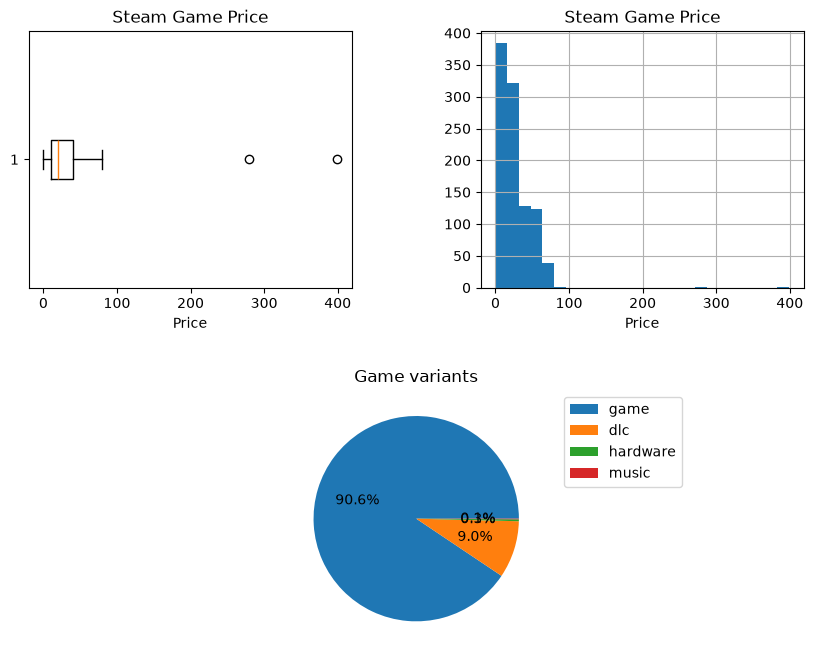

In [68]:
fig = plt.figure(figsize=(10, 8))
gs = fig.add_gridspec(2, 2, wspace=0.4, hspace=0.4)

# Top Left: Box plot, Feature: price
ax1 = fig.add_subplot(gs[0, 0])
ax1.boxplot(df["price"], orientation="horizontal")
ax1.set_title("Steam Game Price")
ax1.set_xlabel("Price")

# Top Right: Histogram, Feature: price
ax2 = fig.add_subplot(gs[0, 1])
ax2.hist(df["price"], bins=25, orientation="vertical")
ax2.set_title("Steam Game Price")
ax2.set_xlabel("Price")
ax2.grid(True)

# Bottom Row: Spans all columns (0 and 1), Feature: Type
ax3 = fig.add_subplot(gs[1, :])
ax3.pie(counts.values,
        autopct="%1.1f%%")
ax3.set_title("Game variants")
ax3.legend(labels=counts.index, 
           bbox_to_anchor=(1.05, 1),    # just outside the right upper edge
           loc="upper left")

## Extract Tag

In [70]:
tags_list = df['Tags'][df['Tags'].notna()]
tag_set = set()

for tags in tags_list:
    tag_list = tags.split(',')
    tag_set.update(tag_list)

print(f'Number of tag recorded: {len(tag_set)}')
print(f'Tag set: {tag_set}')
# Bring the tag set to a file for further purpose
with open('data/SteamGames_tags.txt', 'w') as r:
    for item in tag_set:
        r.write(f'{item}\n') 

Number of tag recorded: 410
Tag set: {'Tower Defense', 'Metroidvania', 'Grand Strategy', 'Military', 'Vehicular Combat', 'Linear', 'Politics', 'Rock Music', 'Music-Based Procedural Generation', 'Team-Based', 'Auto Battler', 'Gore', 'Archery', 'Roguelite', 'Looter Shooter', 'Deckbuilding', 'Top-Down', 'Comic Book', 'Parody', 'Modern', '6DOF', 'Pixel Graphics', 'Philosophical', 'Tactical', 'MOBA', 'Elf', 'Isometric', 'Cute', 'Underground', 'Classic', 'Pirates', 'Platformer', 'Magic', 'Clicker', 'Cyberpunk', 'Touch-Friendly', 'Cult Classic', 'Competitive', 'Fishing', '2D Platformer', 'Bullet Time', 'Steam Machine', 'Soundtrack', 'Retro', 'Shop Keeper', 'Perma Death', 'Immersive', 'Dinosaurs', 'Medical Sim', 'Procedural Generation', 'Rhythm', 'Shooter', 'Creature Collector', 'Solitaire', '3D', 'Golf', 'Crime', 'Noir', 'Dynamic Narration', 'Programming', 'Benchmark', 'Survival Horror', 'Runner', 'Gaming', 'World War II', 'Ambient', 'Hand-drawn', 'Blood', 'Colony Sim', 'Jet', 'Hentai', 'Mahj